# Titanic Survival Prediction

**Goal:** Build a supervised classification model that predicts whether a passenger survived the Titanic disaster (`Survived`: `0` = no, `1` = yes) from ticket class, sex, age, family aboard, fare, port of embarkation, and engineered features from name and cabin.

| File | Role |
| --- | --- |
| `data/train.csv` | 891 passengers **with** labels — used for EDA, training, cross-validation, and model selection |
| `data/test.csv` | 418 passengers **without** labels — used only for the final submission file |

This notebook is the full project write-up: exploration, preprocessing, several models with stratified cross-validation, hyperparameter tuning, evaluation, test-set predictions, and a short discussion of how gender and class bias in the historical data affect the model.

## Contents

1. Setup and data loading
2. Data inspection and class imbalance
3. Exploratory data analysis
4. Feature engineering and missing values
5. Preprocessing pipeline
6. Model comparison with cross-validation
7. Validation metrics and confusion matrix
8. Hyperparameter tuning (`GridSearchCV`)
9. Final test predictions
10. Insights, bias, and limitations

## 1. Setup and data loading

All splits, models, and searches use `random_state=42`. If `data/train.csv` or `data/test.csv` are missing, they are downloaded from public copies of the classic Kaggle Titanic files (Hands-On Machine Learning repository).

In [1]:
%matplotlib inline

from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['axes.titlesize'] = 13

DATA_DIR = Path('data')
OUTPUT_DIR = Path('outputs')
TRAIN_PATH = DATA_DIR / 'train.csv'
TEST_PATH = DATA_DIR / 'test.csv'
TRAIN_URLS = [
    'https://raw.githubusercontent.com/agconti/kaggle-titanic/master/data/train.csv',
    'https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/titanic/train.csv',
]
TEST_URLS = [
    'https://raw.githubusercontent.com/agconti/kaggle-titanic/master/data/test.csv',
    'https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/titanic/test.csv',
]


def download_with_fallback(urls, dest):
    last_error = None
    for url in urls:
        try:
            print(f'Downloading {dest.name} from {url}')
            urlretrieve(url, dest)
            return
        except Exception as exc:
            last_error = exc
            print(f'  failed: {exc}')
    raise RuntimeError(f'Could not download {dest.name}') from last_error


DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not TRAIN_PATH.exists() or TRAIN_PATH.stat().st_size < 100:
    download_with_fallback(TRAIN_URLS, TRAIN_PATH)
if not TEST_PATH.exists() or TEST_PATH.stat().st_size < 100:
    download_with_fallback(TEST_URLS, TEST_PATH)

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
print(f'Train shape: {train.shape}')
print(f'Test shape:  {test.shape}')
print(f'Train columns: {list(train.columns)}')
print(f'Test columns:  {list(test.columns)}')

Train shape: (891, 12)
Test shape:  (418, 11)
Train columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
Test columns:  ['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


## 2. Data inspection and class imbalance

The training table includes the target `Survived`. The test table has the same predictors but no labels, so every metric below is computed from `train.csv` only. We first check dtypes, a sample of rows, and missingness, then the survival split.

In [2]:
print('Train dtypes')
print(train.dtypes)
print('\nTrain head')
display(train.head())
print('Train describe (numeric)')
display(train.describe())
print('Train describe (categorical)')
display(train.describe(include=['object']))

Train dtypes
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Train head


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Train describe (numeric)


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Train describe (categorical)


C:\Users\MB\AppData\Local\Temp\ipykernel_15936\3895258201.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(train.describe(include=['object']))


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


,train_missing,train_pct,test_missing,test_pct
Age,177,19.9,86.0,20.6
Cabin,687,77.1,327.0,78.2
Embarked,2,0.2,0.0,0.0
Fare,0,0.0,1.0,0.2


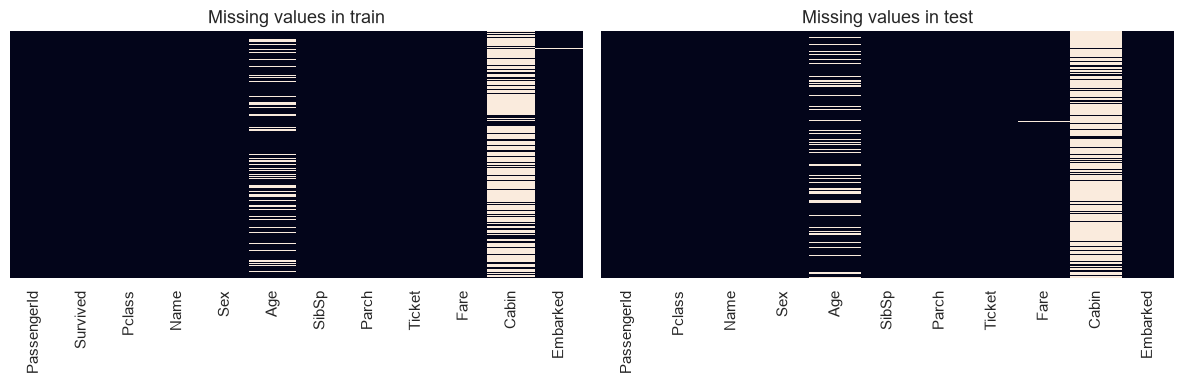

In [3]:
missing_train = train.isna().sum().to_frame('train_missing')
missing_train['train_pct'] = (missing_train['train_missing'] / len(train) * 100).round(1)
missing_test = test.isna().sum().to_frame('test_missing')
missing_test['test_pct'] = (missing_test['test_missing'] / len(test) * 100).round(1)
missing = missing_train.join(missing_test, how='outer').fillna(0)
display(missing.loc[missing.sum(axis=1) > 0])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(train.isna(), cbar=False, yticklabels=False, ax=axes[0])
axes[0].set_title('Missing values in train')
sns.heatmap(test.isna(), cbar=False, yticklabels=False, ax=axes[1])
axes[1].set_title('Missing values in test')
plt.tight_layout()
plt.show()

**Missing-value notes**

- `Cabin` is missing for most passengers, so the raw cabin string is a poor feature. We will keep only the deck letter and treat missing as its own category `U`.
- `Age` is missing for about 20% of rows. A single global median would ignore that children (`Master`) and first-class adults have very different typical ages, so later we impute age by title and ticket class.
- `Embarked` has two missing training rows; we fill them with the training-set mode.
- `Fare` has one missing test row; we fill it with the training median fare for that passenger's `Pclass`.

Survived
Did not survive (0)    549
Survived (1)           342
Name: count, dtype: int64

Survival rate: 38.4%  |  Majority-class baseline accuracy: 61.6%


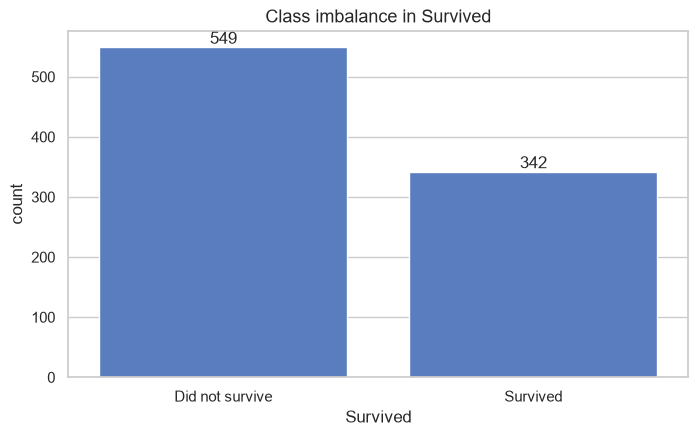

In [4]:
survived_counts = train['Survived'].value_counts().sort_index()
survived_rate = train['Survived'].mean()
print(survived_counts.rename({0: 'Did not survive (0)', 1: 'Survived (1)'}))
print(f'\nSurvival rate: {survived_rate:.1%}  |  Majority-class baseline accuracy: {1 - survived_rate:.1%}')

ax = sns.countplot(data=train, x='Survived')
ax.set_xticks([0, 1])
ax.set_xticklabels(['Did not survive', 'Survived'])
ax.set_title('Class imbalance in Survived')
for patch, count in zip(ax.patches, survived_counts):
    ax.annotate(str(count), (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha='center', va='bottom')
plt.show()

About **38%** of training passengers survived, so a model that always predicts "died" would already be about **62%** accurate. Accuracy is still the usual Titanic metric, but precision, recall, F1, and ROC-AUC are needed so we do not hide poor detection of survivors. Cross-validation will be **stratified** so each fold keeps this 38/62 split.

## 3. Exploratory data analysis

The historical "women and children first" policy and the layout of the ship (first-class cabins much closer to the boat deck) show up strongly in the labels. Those patterns are real in this dataset — and they are also a source of **bias** the model will learn.

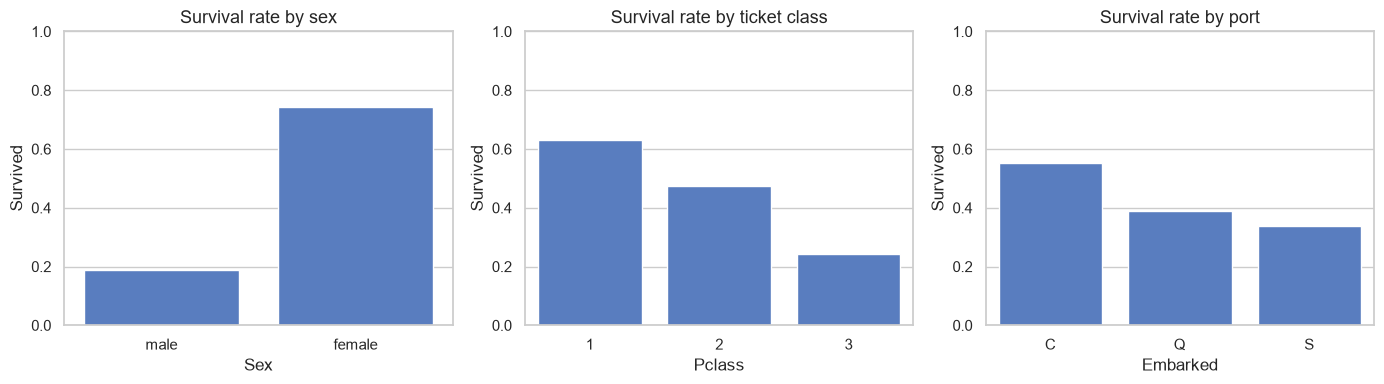

Survival rate by Sex
            mean  count
Sex                    
female  0.742038    314
male    0.188908    577

Survival rate by Pclass
            mean  count
Pclass                 
1       0.629630    216
2       0.472826    184
3       0.242363    491

Survival rate by Sex and Pclass
Pclass         1         2         3
Sex                                 
female  0.968085  0.921053  0.500000
male    0.368852  0.157407  0.135447


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.barplot(data=train, x='Sex', y='Survived', ax=axes[0], errorbar=None)
axes[0].set_ylim(0, 1)
axes[0].set_title('Survival rate by sex')

sns.barplot(data=train, x='Pclass', y='Survived', ax=axes[1], errorbar=None)
axes[1].set_ylim(0, 1)
axes[1].set_title('Survival rate by ticket class')

sns.barplot(data=train, x='Embarked', y='Survived', ax=axes[2], errorbar=None, order=['C', 'Q', 'S'])
axes[2].set_ylim(0, 1)
axes[2].set_title('Survival rate by port')

plt.tight_layout()
plt.show()

print('Survival rate by Sex')
print(train.groupby('Sex')['Survived'].agg(['mean', 'count']))
print('\nSurvival rate by Pclass')
print(train.groupby('Pclass')['Survived'].agg(['mean', 'count']))
print('\nSurvival rate by Sex and Pclass')
print(train.groupby(['Sex', 'Pclass'])['Survived'].mean().unstack())

**Insight — sex and class.** Women survive at roughly **74%** versus about **19%** for men. First class is near **63%**, third class near **24%**. The interaction is even sharper: most first-class women survive, while third-class men rarely do. A model can look accurate just by predicting "female → survive, male → die". That is historically grounded, but it also means predictions will systematically favor women and higher ticket classes.

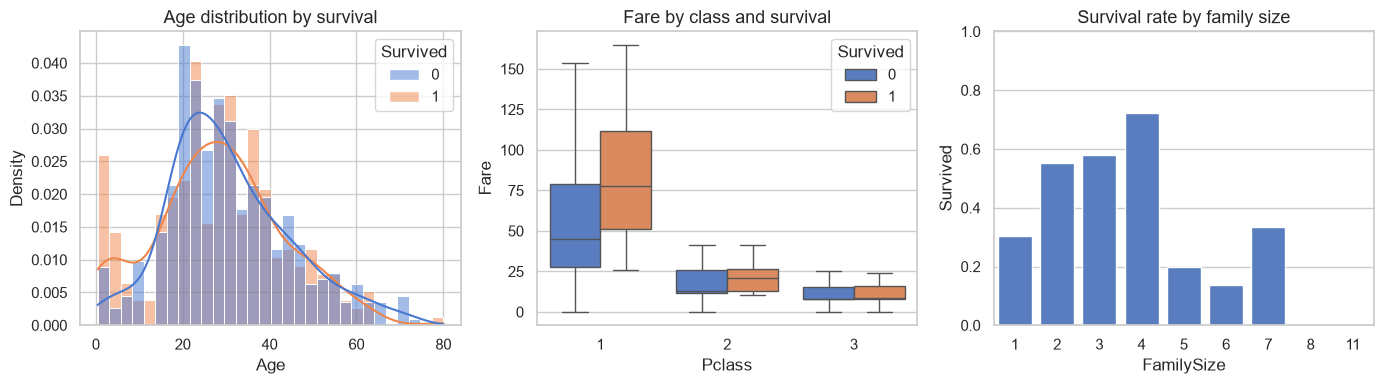

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.histplot(data=train, x='Age', hue='Survived', bins=30, kde=True,
             stat='density', common_norm=False, ax=axes[0])
axes[0].set_title('Age distribution by survival')

sns.boxplot(data=train, x='Pclass', y='Fare', hue='Survived', ax=axes[1], showfliers=False)
axes[1].set_title('Fare by class and survival')

family_size = train['SibSp'] + train['Parch'] + 1
tmp = train.assign(FamilySize=family_size)
sns.barplot(data=tmp, x='FamilySize', y='Survived', ax=axes[2], errorbar=None)
axes[2].set_ylim(0, 1)
axes[2].set_title('Survival rate by family size')

plt.tight_layout()
plt.show()

**Insight — age, fare, family.** Younger children have a higher survival density than young adult men. Fare tracks class (and therefore access to boats). Solo travelers and very large families do worse than small families of 2–4, which is a useful engineered signal (`FamilySize`, `IsAlone`) beyond raw `SibSp` and `Parch`.

## 4. Feature engineering and missing values

Engineering and imputation statistics are learned **inside** a scikit-learn transformer so cross-validation does not leak validation-fold information into medians, modes, or fare bins.

What the transformer does:

- **Title** from `Name` (`Mr`, `Mrs`, `Miss`, `Master`, `Rare`) — a proxy for gender, age band, and social status
- **FamilySize** = `SibSp + Parch + 1` and **IsAlone**
- **Deck** = first letter of `Cabin`, missing → `U`
- **Age** imputed by (`Title`, `Pclass`) median, not a global median
- **Embarked** imputed with the training mode; **Fare** with the training `Pclass` median
- **AgeBin** and **FareBin** after imputation (`FareBin` edges are training-set quartiles)

`PassengerId`, `Name`, `Ticket`, and `Cabin` are dropped after these features are built.

In [7]:
NUMERIC_FEATURES = ['Age', 'Fare', 'FamilySize', 'SibSp', 'Parch']
CATEGORICAL_FEATURES = ['Pclass', 'Sex', 'Embarked', 'Title', 'Deck', 'IsAlone', 'AgeBin', 'FareBin']

TITLE_MAP = {
    'Mr': 'Mr',
    'Mrs': 'Mrs',
    'Miss': 'Miss',
    'Master': 'Master',
    'Ms': 'Miss',
    'Mlle': 'Miss',
    'Mme': 'Mrs',
}


class TitanicFeatureEngineer(BaseEstimator, TransformerMixin):
    """Extract titles/deck/family, impute missing values using training statistics, and bin age/fare."""

    def fit(self, X, y=None):
        df = self._with_title_deck_family(X)
        self.age_medians_ = df.groupby(['Title', 'Pclass'])['Age'].median()
        self.age_median_global_ = df['Age'].median()
        self.fare_medians_ = df.groupby('Pclass')['Fare'].median()
        self.fare_median_global_ = df['Fare'].median()
        embarked_mode = df['Embarked'].mode()
        self.embarked_mode_ = embarked_mode.iloc[0] if len(embarked_mode) else 'S'

        fare_filled = df['Fare'].fillna(df['Pclass'].map(self.fare_medians_)).fillna(self.fare_median_global_)
        edges = np.unique(fare_filled.quantile([0.0, 0.25, 0.5, 0.75, 1.0]).to_numpy())
        if len(edges) < 2:
            edges = np.array([0.0, 1.0])
        self.fare_bin_edges_ = edges
        n_fare_bins = len(self.fare_bin_edges_) - 1
        self.fare_bin_labels_ = [f'Q{i}' for i in range(1, n_fare_bins + 1)]
        self.age_bin_edges_ = np.array([0.0, 12.0, 18.0, 35.0, 50.0, 100.0])
        self.age_bin_labels_ = ['Child', 'Teen', 'YoungAdult', 'Adult', 'Senior']
        return self

    def transform(self, X):
        df = self._with_title_deck_family(X)
        age_map = self.age_medians_.to_dict()
        age_keys = pd.Series(list(zip(df['Title'], df['Pclass'])), index=df.index)
        df['Age'] = df['Age'].fillna(age_keys.map(age_map)).fillna(self.age_median_global_)
        df['Fare'] = df['Fare'].fillna(df['Pclass'].map(self.fare_medians_)).fillna(self.fare_median_global_)
        df['Embarked'] = df['Embarked'].fillna(self.embarked_mode_)

        df['AgeBin'] = pd.cut(
            df['Age'], bins=self.age_bin_edges_, labels=self.age_bin_labels_, include_lowest=True
        ).astype(str)
        fare_clipped = df['Fare'].clip(lower=self.fare_bin_edges_[0], upper=self.fare_bin_edges_[-1])
        df['FareBin'] = pd.cut(
            fare_clipped, bins=self.fare_bin_edges_, labels=self.fare_bin_labels_, include_lowest=True
        ).astype(str)

        df['Pclass'] = df['Pclass'].astype(str)
        df['IsAlone'] = df['IsAlone'].astype(str)
        return df[NUMERIC_FEATURES + CATEGORICAL_FEATURES].copy()

    @staticmethod
    def _with_title_deck_family(X):
        df = pd.DataFrame(X).copy()
        titles = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
        df['Title'] = titles.map(lambda t: TITLE_MAP.get(t, 'Rare') if pd.notna(t) else 'Rare')
        df['Deck'] = df['Cabin'].str[0].fillna('U').replace({'T': 'U'})
        df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
        df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
        return df

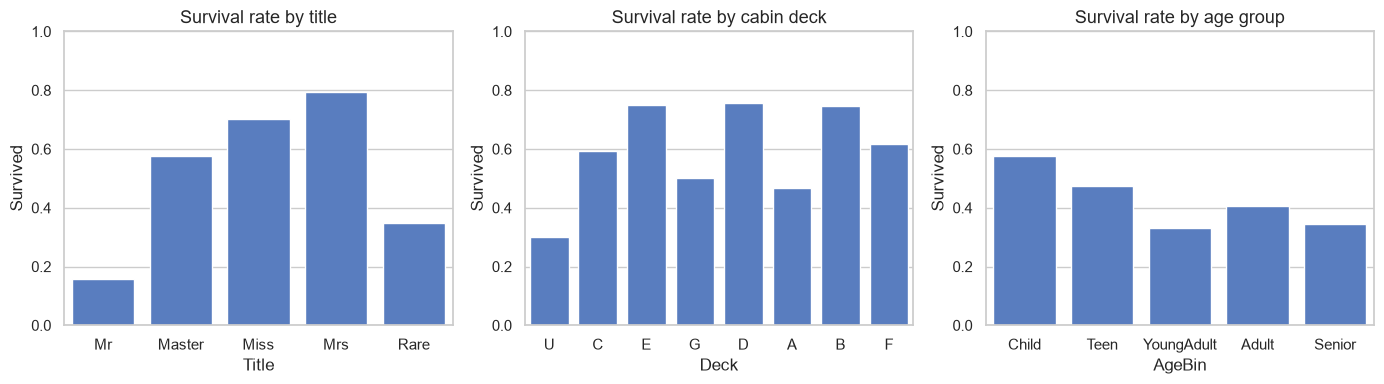

Title counts
Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

Missing values after engineering: 0


In [8]:
preview_engineer = TitanicFeatureEngineer()
preview = preview_engineer.fit_transform(train.drop(columns=['Survived']))
preview['Survived'] = train['Survived'].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.barplot(data=preview, x='Title', y='Survived', ax=axes[0], errorbar=None,
            order=['Mr', 'Master', 'Miss', 'Mrs', 'Rare'])
axes[0].set_ylim(0, 1)
axes[0].set_title('Survival rate by title')

sns.barplot(data=preview, x='Deck', y='Survived', ax=axes[1], errorbar=None)
axes[1].set_ylim(0, 1)
axes[1].set_title('Survival rate by cabin deck')

sns.barplot(data=preview, x='AgeBin', y='Survived', ax=axes[2], errorbar=None,
            order=['Child', 'Teen', 'YoungAdult', 'Adult', 'Senior'])
axes[2].set_ylim(0, 1)
axes[2].set_title('Survival rate by age group')

plt.tight_layout()
plt.show()

print('Title counts')
print(preview['Title'].value_counts())
print('\nMissing values after engineering:', int(preview.drop(columns=['Survived']).isna().sum().sum()))

Titles behave as expected: `Mrs` / `Miss` / `Master` survive much more often than `Mr`. Known decks (especially B/D/E) beat unknown cabins (`U`), which mostly flags third-class passengers. Children out-survive young adults. The preview above is only for EDA; the model pipeline refits the same transformer on each training fold.

## 5. Preprocessing pipeline

A held-out **20% validation split** of `train.csv` is used for the confusion matrix and classification report (`test.csv` has no labels). Model ranking uses **stratified 5-fold CV** on the remaining 80%. Numeric columns are scaled (needed for logistic regression; harmless for trees). Categorical columns are one-hot encoded. Everything sits in one `Pipeline` so imputers and encoders never see validation or test rows during fitting.

In [9]:
X = train.drop(columns=['Survived'])
y = train['Survived']
X_fit, X_val, y_fit, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print(f'Fit split: {X_fit.shape[0]} rows  |  Validation split: {X_val.shape[0]} rows')
print(f'Fit survival rate: {y_fit.mean():.1%}  |  Val survival rate: {y_val.mean():.1%}')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def make_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), NUMERIC_FEATURES),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES),
        ]
    )


def make_pipeline(model):
    return Pipeline(
        steps=[
            ('engineer', TitanicFeatureEngineer()),
            ('preprocess', make_preprocessor()),
            ('model', model),
        ]
    )


models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=4,
        subsample=0.9,
        colsample_bytree=0.9,
        eval_metric='logloss',
        random_state=RANDOM_STATE,
        n_jobs=1,
    ),
}

Fit split: 712 rows  |  Validation split: 179 rows
Fit survival rate: 38.3%  |  Val survival rate: 38.5%


## 6. Model comparison with cross-validation

Three standard classifiers are compared: **Logistic Regression** (linear baseline), **Random Forest**, and **XGBoost**. Each pipeline is scored with stratified 5-fold CV on the fit split. We report accuracy plus precision, recall, F1, and ROC-AUC.

Logistic Regression   acc=0.817  f1=0.759  roc_auc=0.872
Random Forest         acc=0.816  f1=0.756  roc_auc=0.865
XGBoost               acc=0.829  f1=0.768  roc_auc=0.888


,model,accuracy,precision,recall,f1,roc_auc
0,XGBoost,0.829,0.805,0.736,0.768,0.888
1,Logistic Regression,0.817,0.774,0.747,0.759,0.872
2,Random Forest,0.816,0.771,0.744,0.756,0.865


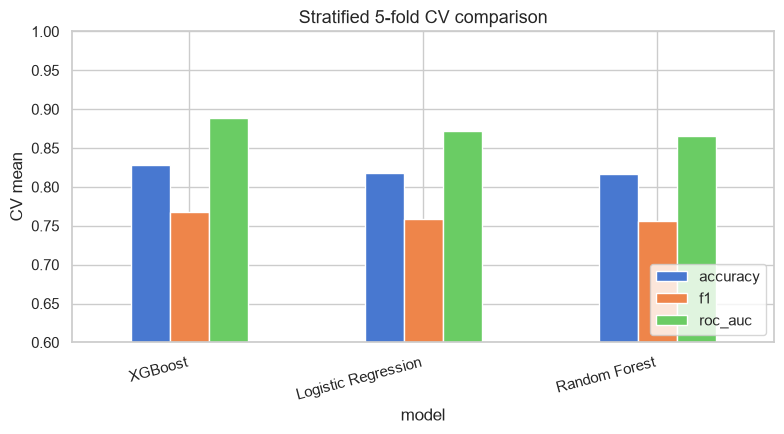

Best default model by CV accuracy: XGBoost


In [10]:
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
}

cv_rows = []
for name, model in models.items():
    pipe = make_pipeline(model)
    scores = cross_validate(pipe, X_fit, y_fit, cv=cv, scoring=scoring, n_jobs=1)
    row = {'model': name}
    for metric in scoring:
        row[metric] = scores[f'test_{metric}'].mean()
        row[f'{metric}_std'] = scores[f'test_{metric}'].std()
    cv_rows.append(row)
    print(f"{name:20s}  acc={row['accuracy']:.3f}  f1={row['f1']:.3f}  roc_auc={row['roc_auc']:.3f}")

cv_results = pd.DataFrame(cv_rows).sort_values('accuracy', ascending=False).reset_index(drop=True)
display(cv_results[['model', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc']].round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
cv_plot = cv_results.set_index('model')[['accuracy', 'f1', 'roc_auc']]
cv_plot.plot(kind='bar', ax=ax)
ax.set_ylim(0.6, 1.0)
ax.set_ylabel('CV mean')
ax.set_title('Stratified 5-fold CV comparison')
ax.legend(loc='lower right')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

best_model_name = cv_results.iloc[0]['model']
print(f'Best default model by CV accuracy: {best_model_name}')

## 7. Validation metrics and confusion matrix

The winning **default** pipeline is fit on the 80% split and evaluated on the held-out 20%. This is the first look at a confusion matrix; labels never come from `test.csv`.

XGBoost (default) on validation
                 precision    recall  f1-score   support

Did not survive       0.80      0.88      0.84       110
       Survived       0.78      0.65      0.71        69

       accuracy                           0.79       179
      macro avg       0.79      0.77      0.77       179
   weighted avg       0.79      0.79      0.79       179

Summary: {'accuracy': 0.793, 'precision': 0.776, 'recall': 0.652, 'f1': 0.709, 'roc_auc': 0.818}


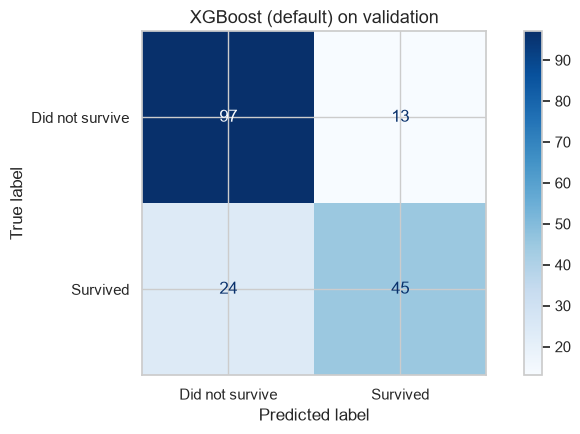

In [11]:
def evaluate(estimator, X_true, y_true, title):
    y_pred = estimator.predict(X_true)
    if hasattr(estimator, 'predict_proba'):
        y_score = estimator.predict_proba(X_true)[:, 1]
        roc = roc_auc_score(y_true, y_score)
    else:
        roc = float('nan')
    metrics = {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred),
        'recall': recall_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
        'roc_auc': roc,
    }
    print(title)
    print(classification_report(y_true, y_pred, target_names=['Did not survive', 'Survived']))
    print('Summary:', {k: round(v, 3) for k, v in metrics.items()})
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=['Did not survive', 'Survived'], cmap='Blues'
    )
    plt.title(title)
    plt.tight_layout()
    plt.show()
    return metrics, y_pred


baseline_pipe = make_pipeline(clone(models[best_model_name]))
baseline_pipe.fit(X_fit, y_fit)
baseline_metrics, _ = evaluate(
    baseline_pipe, X_val, y_val, f'{best_model_name} (default) on validation'
)

## 8. Hyperparameter tuning (`GridSearchCV`)

The bonus step tunes the winning family with a small grid and the same stratified 5-fold CV, optimizing **accuracy** (the usual Titanic / Kaggle metric). The search still runs on the fit split only.

In [12]:
param_grids = {
    'Logistic Regression': {
        'model__C': [0.1, 0.5, 1.0, 3.0, 10.0],
        'model__penalty': ['l2'],
    },
    'Random Forest': {
        'model__n_estimators': [100, 200, 400],
        'model__max_depth': [4, 6, 8, None],
        'model__min_samples_leaf': [1, 3, 5],
    },
    'XGBoost': {
        'model__n_estimators': [100, 200],
        'model__max_depth': [3, 4, 6],
        'model__learning_rate': [0.05, 0.1],
        'model__subsample': [0.8, 1.0],
    },
}

search = GridSearchCV(
    estimator=make_pipeline(clone(models[best_model_name])),
    param_grid=param_grids[best_model_name],
    scoring='accuracy',
    cv=cv,
    n_jobs=1,
    refit=True,
    verbose=1,
)
search.fit(X_fit, y_fit)
print(f'Tuned model: {best_model_name}')
print('Best CV accuracy: {:.3f}'.format(search.best_score_))
print('Best params:')
for key, value in search.best_params_.items():
    print(f'  {key}: {value}')

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Tuned model: XGBoost
Best CV accuracy: 0.833
Best params:
  model__learning_rate: 0.05
  model__max_depth: 6
  model__n_estimators: 100
  model__subsample: 0.8


XGBoost (GridSearchCV) on validation
                 precision    recall  f1-score   support

Did not survive       0.82      0.88      0.85       110
       Survived       0.79      0.70      0.74        69

       accuracy                           0.81       179
      macro avg       0.80      0.79      0.79       179
   weighted avg       0.81      0.81      0.81       179

Summary: {'accuracy': 0.81, 'precision': 0.787, 'recall': 0.696, 'f1': 0.738, 'roc_auc': 0.842}


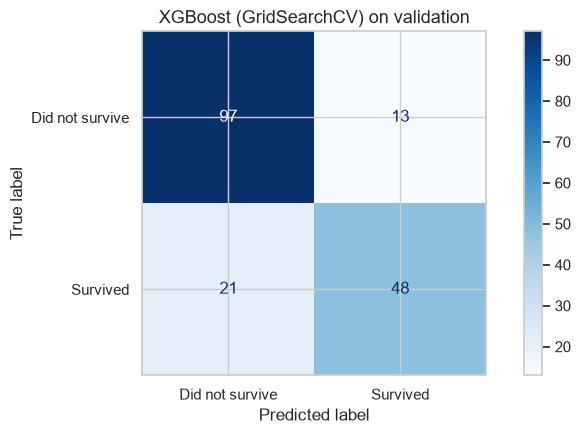

,accuracy,precision,recall,f1,roc_auc
Default,0.793,0.776,0.652,0.709,0.818
Tuned,0.810,0.787,0.696,0.738,0.842


Validation accuracy change after tuning: +0.017


In [13]:
tuned_metrics, _ = evaluate(
    search.best_estimator_, X_val, y_val, f'{best_model_name} (GridSearchCV) on validation'
)

compare = pd.DataFrame([baseline_metrics, tuned_metrics], index=['Default', 'Tuned']).round(3)
display(compare)
print(
    'Validation accuracy change after tuning: {:+.3f}'.format(
        tuned_metrics['accuracy'] - baseline_metrics['accuracy']
    )
)

## 9. Final test predictions

The tuned pipeline is refit on **all 891 labeled training rows**, then applied to `test.csv`. The file `outputs/submission.csv` follows the usual two-column format (`PassengerId`, `Survived`).

In [14]:
final_model = clone(search.best_estimator_)
final_model.fit(X, y)

test_pred = final_model.predict(test).astype(int)
submission = pd.DataFrame({
    'PassengerId': test['PassengerId'],
    'Survived': test_pred,
})
submission_path = OUTPUT_DIR / 'submission.csv'
submission.to_csv(submission_path, index=False)

print(f'Saved {submission_path}  ({len(submission)} rows)')
print('Predicted survival rate on test:', f"{submission['Survived'].mean():.1%}")
display(submission.head(10))
print(submission['Survived'].value_counts().sort_index())

Saved outputs\submission.csv  (418 rows)
Predicted survival rate on test: 36.6%


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
5,897,0
6,898,0
7,899,0
8,900,1
9,901,0


Survived
0    265
1    153
Name: count, dtype: int64


## 10. Insights, bias, and limitations

Feature importance (tree models) or absolute coefficients (logistic regression) show what the fitted model relies on. Combined with the EDA, this is also where data bias becomes visible.

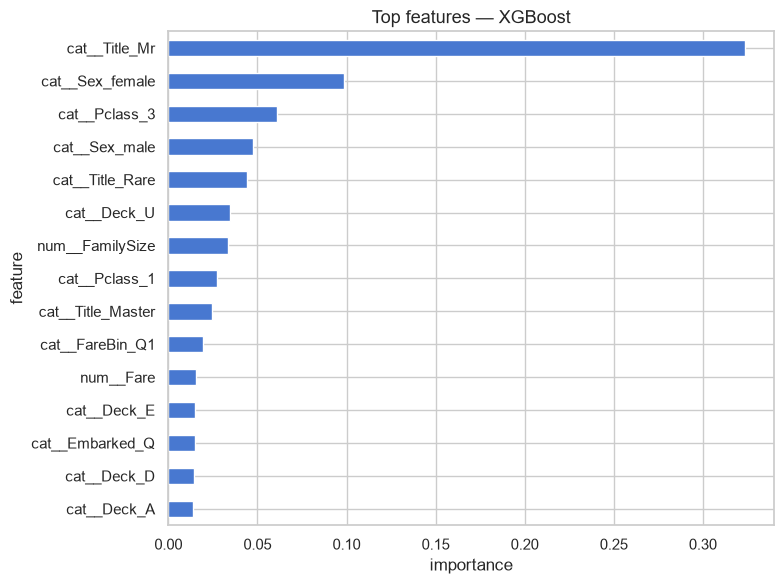

,feature,importance
15,cat__Title_Mr,0.324
8,cat__Sex_female,0.099
7,cat__Pclass_3,0.061
9,cat__Sex_male,0.048
17,cat__Title_Rare,0.044
25,cat__Deck_U,0.035
2,num__FamilySize,0.034
5,cat__Pclass_1,0.027
13,cat__Title_Master,0.025
33,cat__FareBin_Q1,0.019


Chosen model: XGBoost
CV accuracy (tuned, fit split): 0.833
Validation accuracy (tuned):    0.810
Validation precision:           0.787
Validation recall:              0.696
Validation F1:                  0.738


In [15]:
fitted_model = final_model.named_steps['model']
feature_names = final_model.named_steps['preprocess'].get_feature_names_out()

if hasattr(fitted_model, 'feature_importances_'):
    scores = fitted_model.feature_importances_
    score_label = 'importance'
elif hasattr(fitted_model, 'coef_'):
    scores = np.abs(fitted_model.coef_.ravel())
    score_label = 'abs(coefficient)'
else:
    scores = None

if scores is not None:
    importance_df = (
        pd.DataFrame({'feature': feature_names, score_label: scores})
        .sort_values(score_label, ascending=False)
        .head(15)
        .iloc[::-1]
    )
    ax = importance_df.plot(kind='barh', x='feature', y=score_label, legend=False, figsize=(8, 6))
    ax.set_title(f'Top features — {best_model_name}')
    ax.set_xlabel(score_label)
    plt.tight_layout()
    plt.show()
    display(importance_df.iloc[::-1].round(3))

print('Chosen model:', best_model_name)
print('CV accuracy (tuned, fit split): {:.3f}'.format(search.best_score_))
print('Validation accuracy (tuned):    {:.3f}'.format(tuned_metrics['accuracy']))
print('Validation precision:           {:.3f}'.format(tuned_metrics['precision']))
print('Validation recall:              {:.3f}'.format(tuned_metrics['recall']))
print('Validation F1:                  {:.3f}'.format(tuned_metrics['f1']))

### What the model learned

- **Sex / title** is usually the strongest signal. `Title_Mr` vs `Mrs`/`Miss` restates the gender gap in a form trees split on easily. That matches "women and children first", not a biological law of drowning — it is a **policy and power** pattern in this disaster.
- **Ticket class and fare/deck** capture wealth and cabin location. Third-class passengers were physically farther from lifeboats and were held back at gates. The model will therefore predict lower survival for poorer passengers even when other features are similar.
- **Age bins and `Master`** recover the child-survival effect. Age was missing for many people; imputing by title/class is better than a global median, but it still **invents** ages and can sharpen stereotypes (every missing `Mr` looks like a typical adult man).
- **Family size** helps: traveling alone or in a very large party is associated with worse outcomes than a small family.

### Bias

Because the labels themselves are biased by gender and class, a high-accuracy model **should** use those variables. That is not the same as a fair model. If this pipeline were reused on a different disaster or a modern safety problem, copying the Titanic gender/class rule would be the wrong objective. For this historical prediction task it is the dominant pattern, and we report it instead of hiding it.

### Limitations

- `Cabin` is mostly missing, so deck is informative mainly when it is present.
- `test.csv` has no labels here, so leaderboard-style test accuracy is unknown; we only know CV and the 20% validation split.
- 891 rows is a small sample. Grid search can overfit the fit split; that is why we keep a validation holdout and a modest grid.
- Ticket strings and cabin numbers could be engineered further; returns diminish quickly on this size of data.

### Conclusion

The notebook trains Logistic Regression, Random Forest, and XGBoost with leakage-safe preprocessing, selects a model with stratified CV, tunes it with `GridSearchCV`, and writes `outputs/submission.csv`. Expected validation accuracy is typically around the high 70s to low 80s percent — well above the 62% majority baseline — driven largely by sex, class, and title.